In [1]:
import sys
import utils as utils
from importlib import reload
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
reload(utils)
from tqdm import tqdm
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import plotting as plt_AMM

In [2]:
import warnings
warnings.filterwarnings("ignore")

In [3]:
%load_ext autoreload
%autoreload 2

In [4]:
import matplotlib.pylab as pylab
params = {'legend.fontsize': 'x-large',
          'figure.figsize': (8, 5),
         'axes.labelsize': 'x-large',
         'axes.titlesize':'x-large',
         'xtick.labelsize':'x-large',
         'ytick.labelsize':'x-large'}
pylab.rcParams.update(params)
%config InlineBackend.figure_format = "retina"

import matplotlib
plt.rc('text', usetex=True)
plt.rc('text.latex', preamble=r'\usepackage{amsmath,amsfonts}')
dpi = 300

## Load parameters

In [5]:
import pickle

with open('data/params_env.pkl', 'rb') as f:
    params_env = pickle.load(f)

In [6]:
params_env

{'sigma': 160.458,
 'S0': 2820.0,
 'Z0': 2820.0,
 'Y0': 50000,
 'eta': 1e-10,
 'xi': 300,
 'T': 1.0,
 'a1': 142.712,
 'a2': 0.0,
 'a3': 13.568,
 'Nt': 10000,
 'fee': 0.0,
 'feeV': 8460.0,
 'C': 0.0,
 'gamma': 1e-10,
 'zeta': 1e-10,
 'tempLP': 1e-14,
 'P0': 0.0}

In [7]:
#params_env['P0'] = -3e6
params_env['zeta'] = 1e-6
params_env['gamma'] = 1e-18

params_env['a2'] = 1e-5
params_env['tempLP'] = 5e-6

## Define environment

In [8]:
env = utils.environment_exp(**params_env)
risk_type = 'averse'

In [9]:
mins_per_step = 24*60/10_000

In [10]:
np.random.seed(100)

nsims = 1_000
strag_LP = '1'
strag_vn = 'exp'

S, Y, Z, X, nu, wealth, perf, rew, venue_wealth, A_a_hist, A_b_hist, A_W_hist, A_B_hist, rew_drift_hist = env.simulate_venue(nsims=nsims, strag_LP=strag_LP, strag_vn=strag_vn, verbose = True)

In [11]:
mins_per_step = 24*60/10_000
Nwindow = int(10/mins_per_step)

df = pd.DataFrame(data=np.concatenate((S.ravel().reshape(-1,1),Z.ravel().reshape(-1,1)),axis=1), columns=('S','Z'))
df['difference'] = df['S'] - df['Z']
diffs = df['difference'].rolling(Nwindow).mean()
diffs.dropna(inplace=True)

In [12]:
fs = 14
fsL = 19
plt.rcParams["font.size"] = fs

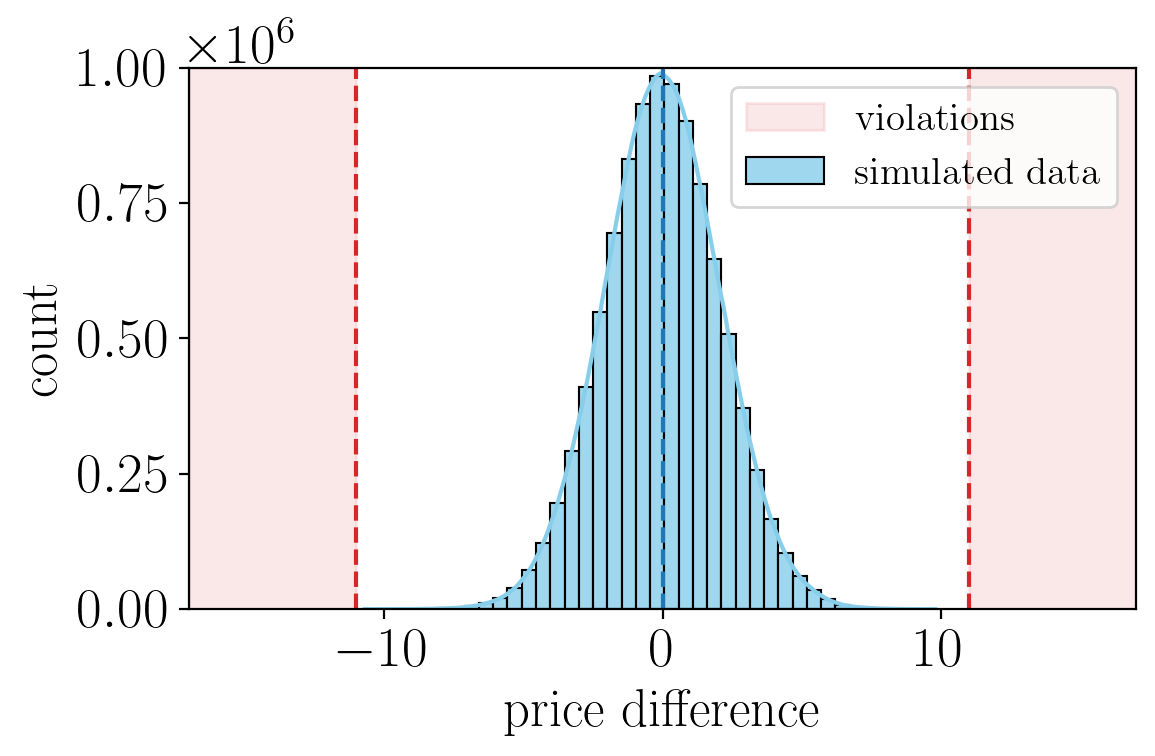

In [13]:
import seaborn as sns
fig, axs = plt.subplots(1, 1, sharex=True, figsize=(6,4))

x = -10.994492750981774

sns.histplot(data=diffs, bins=40, kde=True, color="skyblue", label = r'$\mathrm{simulated}$ $\mathrm{data}$', ax=axs, alpha =0.8)
axs.set_xlabel(r'$\mathrm{price\,\,difference}$', fontsize = fsL)
axs.set_ylabel(r'$\mathrm{count}$', fontsize = fsL)

axs.axvline(0,linestyle = '--', color='tab:blue')
axs.axvline(x,linestyle = '--', color='tab:red')
axs.axvline(-x,linestyle = '--', color='tab:red')

xmin = -17
xmax = 17
ymax = 1_000_000

xaux_left = np.linspace(xmin, x, 100)
xaux_right = np.linspace(-x, xmax, 100)

axs.fill_between(xaux_left, ymax*np.ones_like(xaux_left), color = 'tab:red' , alpha=0.1, label= r'$\mathrm{violations}$')
axs.fill_between(xaux_right, ymax*np.ones_like(xaux_right), color = 'tab:red' , alpha=0.1)

plt.ylim([0,ymax])
plt.tight_layout()
plt.xlim([xmin,xmax])
plt.legend(fontsize=fs)

plt.tight_layout()
plt.savefig(f'figures/negative-intensity-regions-real-symm-simulations-{risk_type}.pdf', format="pdf", dpi=dpi)
plt.show()

In [14]:
(diffs.values> -x).sum() + (diffs.values< x).sum()

0

In [15]:
qtl_Y = np.zeros((len(env.timesteps),3))
qtl_nu = np.zeros((len(env.timesteps),3))

dt = env.timesteps[1] - env.timesteps[0]
qtl_dQ = np.zeros((len(env.timesteps),3))
dQ = dt * np.cumsum(nu[:,:], axis = 0)

qtl_rew = np.zeros((len(env.timesteps),3))
qtl_Z = np.zeros((len(env.timesteps),3))
qtl_S = np.zeros((len(env.timesteps),3))

for it, t in enumerate(env.timesteps):
    qtl_Y[it, :] = np.quantile(Y[it,:],[0.05,0.5,0.95],axis=0)
    qtl_nu[it, :] = np.quantile(nu[it,:],[0.05,0.5,0.95],axis=0)
    qtl_dQ[it, :] = np.quantile(dQ[it,:],[0.05,0.5,0.95],axis=0)
    qtl_rew[it, :] = np.quantile(rew[it,:],[0.05,0.5,0.95],axis=0)
    qtl_Z[it, :] = np.quantile(Z[it,:],[0.05,0.5,0.95],axis=0)
    qtl_S[it, :] = np.quantile(S[it,:],[0.05,0.5,0.95],axis=0)

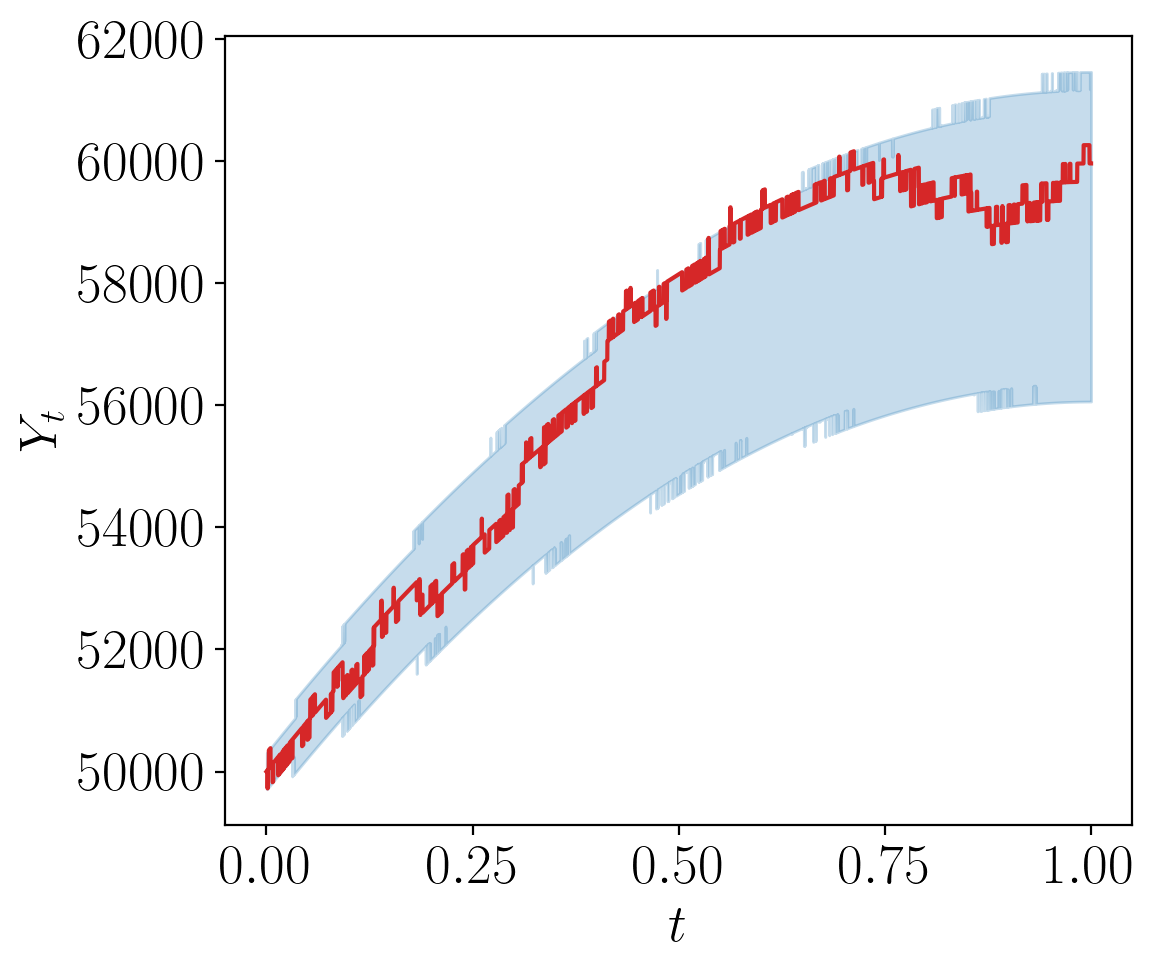

In [16]:
nsim = 53

fig, axs = plt.subplots(1, 1, sharex=True, figsize=(6,5))
plt.plot(env.timesteps, Y[:,nsim], label=r'$Y$', color ='tab:red')
plt.fill_between(env.timesteps,qtl_Y[:,0],qtl_Y[:,-1], color='tab:blue', alpha=0.25)
plt.xlabel(r'$t$', fontsize = fsL)
plt.ylabel(r'$Y_t$', fontsize = fsL)
plt.tight_layout()
plt.savefig(f'figures/baseline-real-sim-Y-paths-{risk_type}.pdf', format="pdf", dpi=dpi)
plt.show()

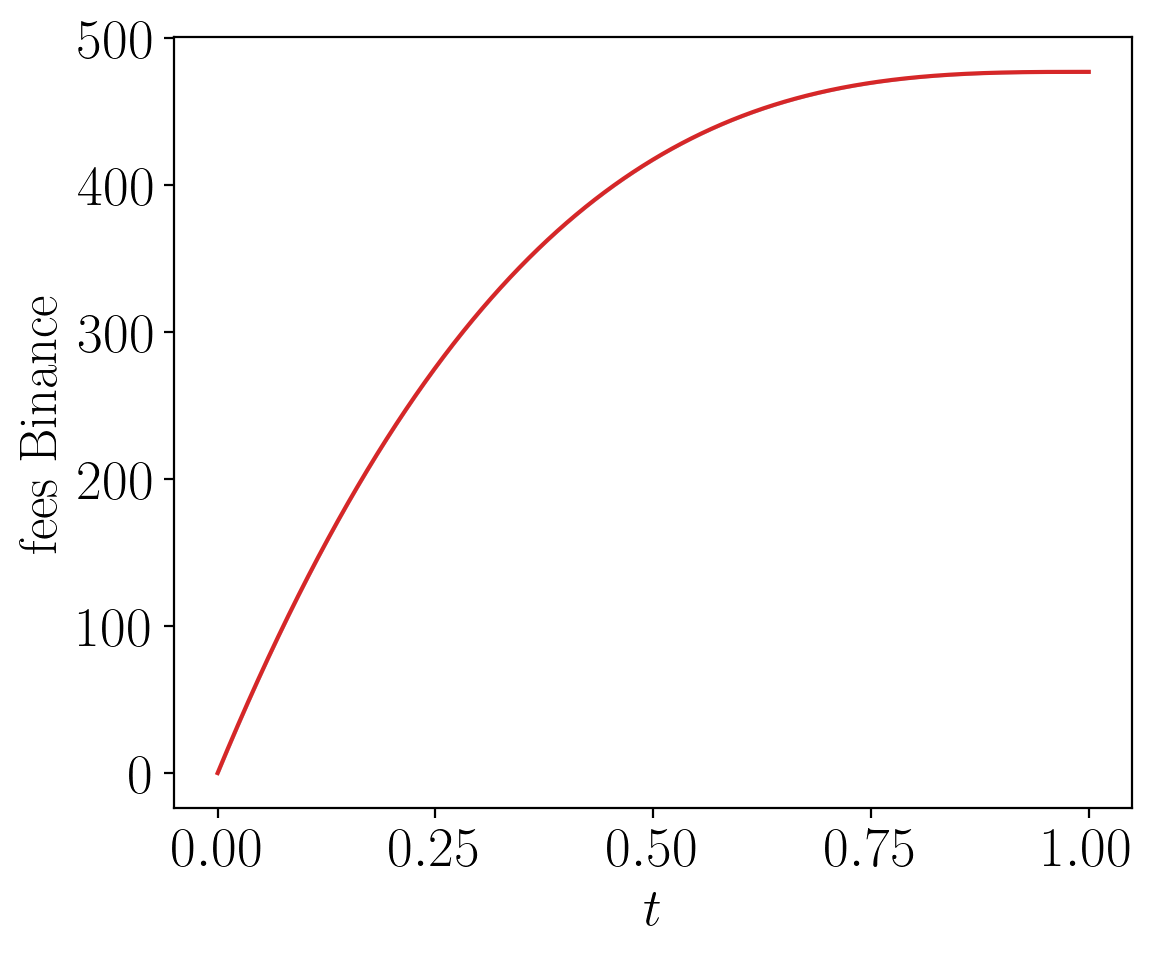

In [17]:
fees_paid_to_Binance = np.cumsum(dt*params_env['tempLP']*(nu ** 2),axis=0)
qtl_fees = np.zeros((len(env.timesteps),3))

for it, t in enumerate(env.timesteps):
    qtl_fees[it, :] = np.quantile(fees_paid_to_Binance[it,:],[0.05,0.5,0.95],axis=0)
nsim = 53

fig, axs = plt.subplots(1, 1, sharex=True, figsize=(6,5))
plt.plot(env.timesteps, fees_paid_to_Binance[:,nsim], label=r'$Y$', color ='tab:red')
plt.fill_between(env.timesteps,qtl_fees[:,0],qtl_fees[:,-1], color='tab:blue', alpha=0.25)
plt.xlabel(r'$t$', fontsize = fsL)
plt.ylabel(r'$\mathrm{fees}$~$\mathrm{Binance}$', fontsize = fsL)
plt.tight_layout()
plt.savefig(f'figures/baseline-real-fees-Binance-{risk_type}.pdf', format="pdf", dpi=dpi)
plt.show()

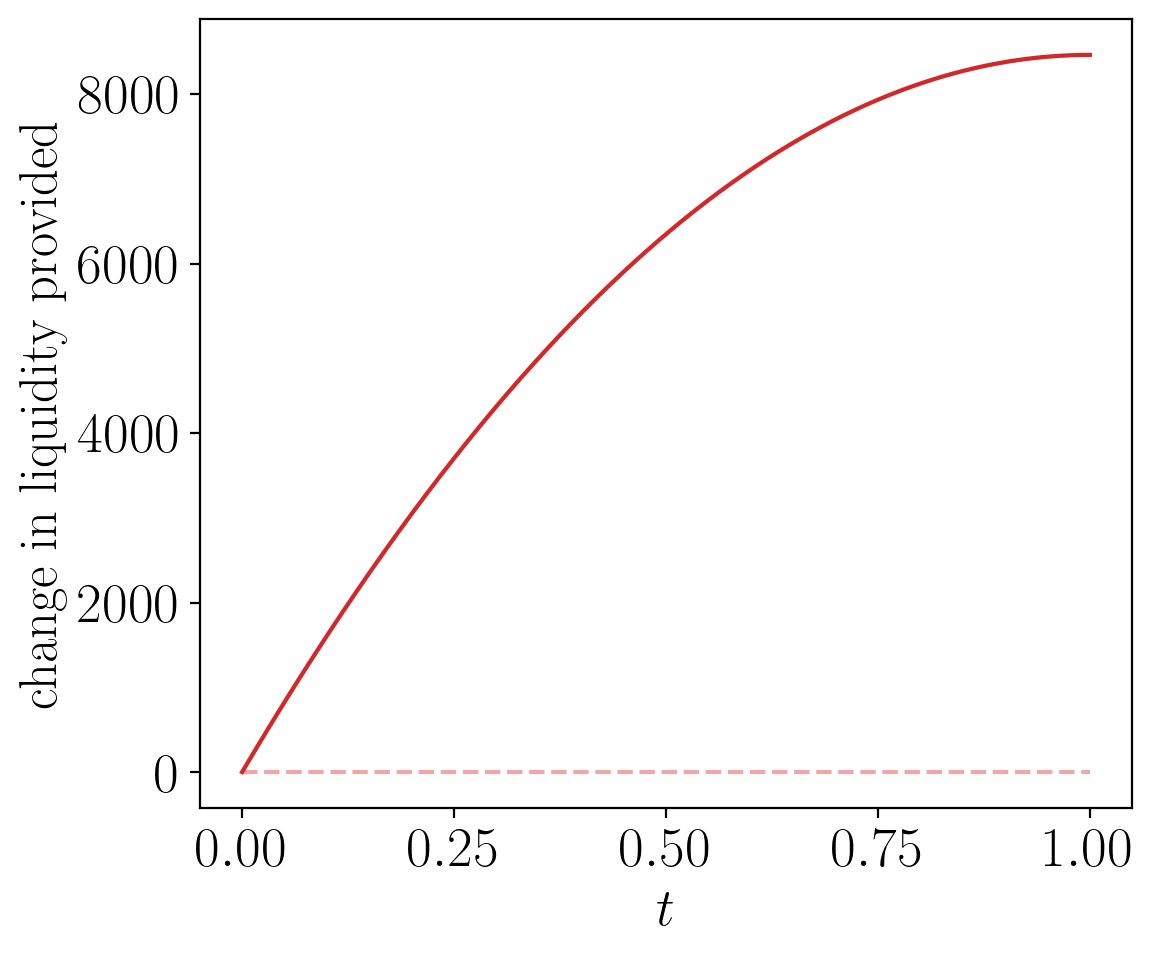

In [18]:
fig, axs = plt.subplots(1, 1, sharex=True, figsize=(6,5))
plt.plot(env.timesteps, dt * np.cumsum(nu[:,nsim],axis=0), label=r'$\nu$', color ='tab:red')
plt.fill_between(env.timesteps,qtl_dQ[:,0],qtl_dQ[:,-1], color='tab:blue', alpha=0.25)
plt.xlabel(r'$t$', fontsize = fsL)
plt.ylabel(r'$\mathrm{change}$~$\mathrm{in}$~$\mathrm{liquidity}$~$\mathrm{provided}$', fontsize = fsL)
plt.hlines(y = 0, xmin = 0, xmax = 1, linestyle = '--', alpha = 0.4, color='tab:red')
#plt.xlim([0,0.1])
plt.tight_layout()
plt.savefig(f'figures/baseline-real-sim-cumnu-paths-{risk_type}.pdf', format="pdf", dpi=dpi)
plt.show()

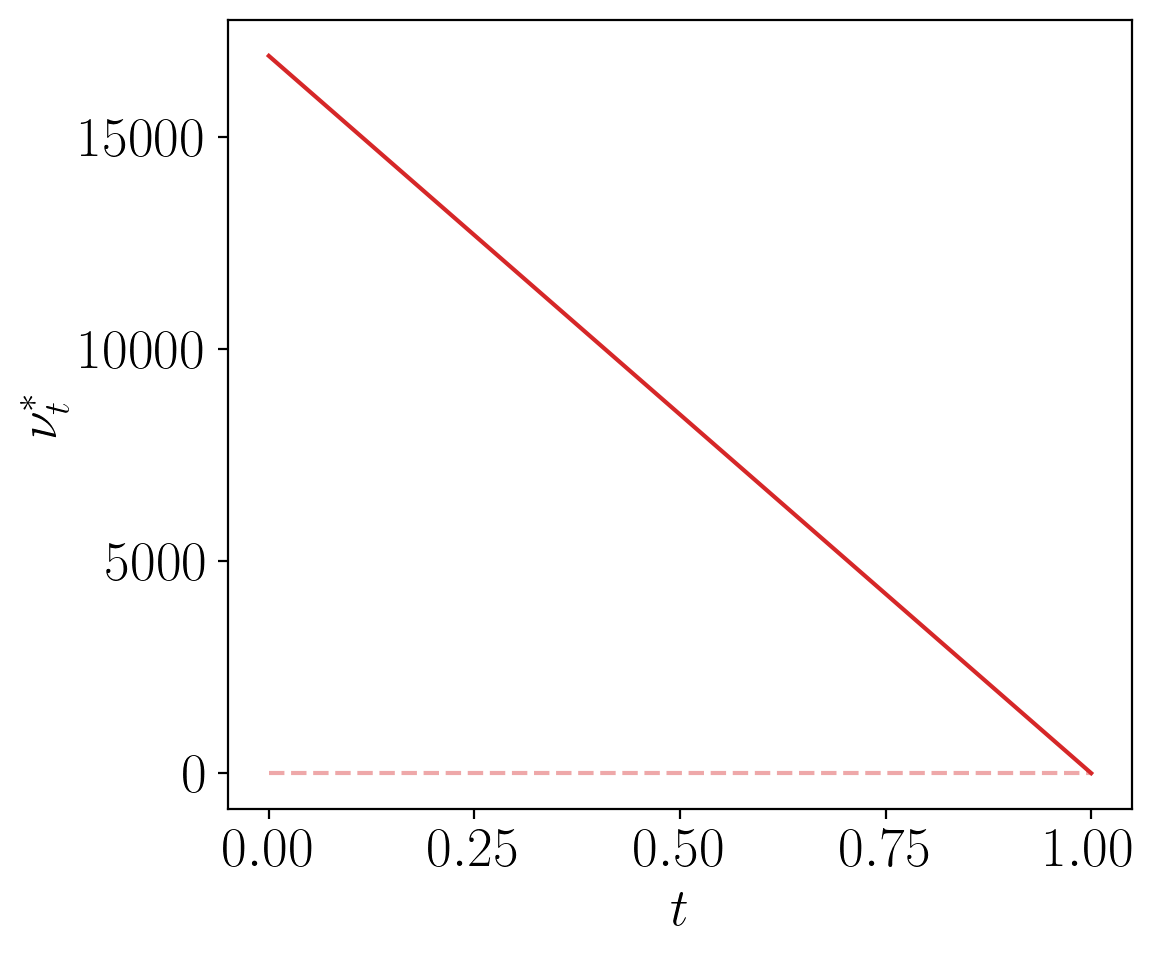

In [19]:
fig, axs = plt.subplots(1, 1, sharex=True, figsize=(6,5))
plt.plot(env.timesteps, nu[:,nsim], label=r'$\nu$', color ='tab:red')
plt.fill_between(env.timesteps,qtl_nu[:,0],qtl_nu[:,-1], color='tab:blue', alpha=0.25)
plt.xlabel(r'$t$', fontsize = fsL)
plt.ylabel(r'$\nu^*_t$', fontsize = fsL)
plt.hlines(y = 0, xmin = 0, xmax = 1, linestyle = '--', alpha = 0.4, color='tab:red')
#plt.xlim([0,0.1])
plt.tight_layout()
plt.savefig(f'figures/baseline-real-sim-nu-paths-{risk_type}.pdf', format="pdf", dpi=dpi)
plt.show()

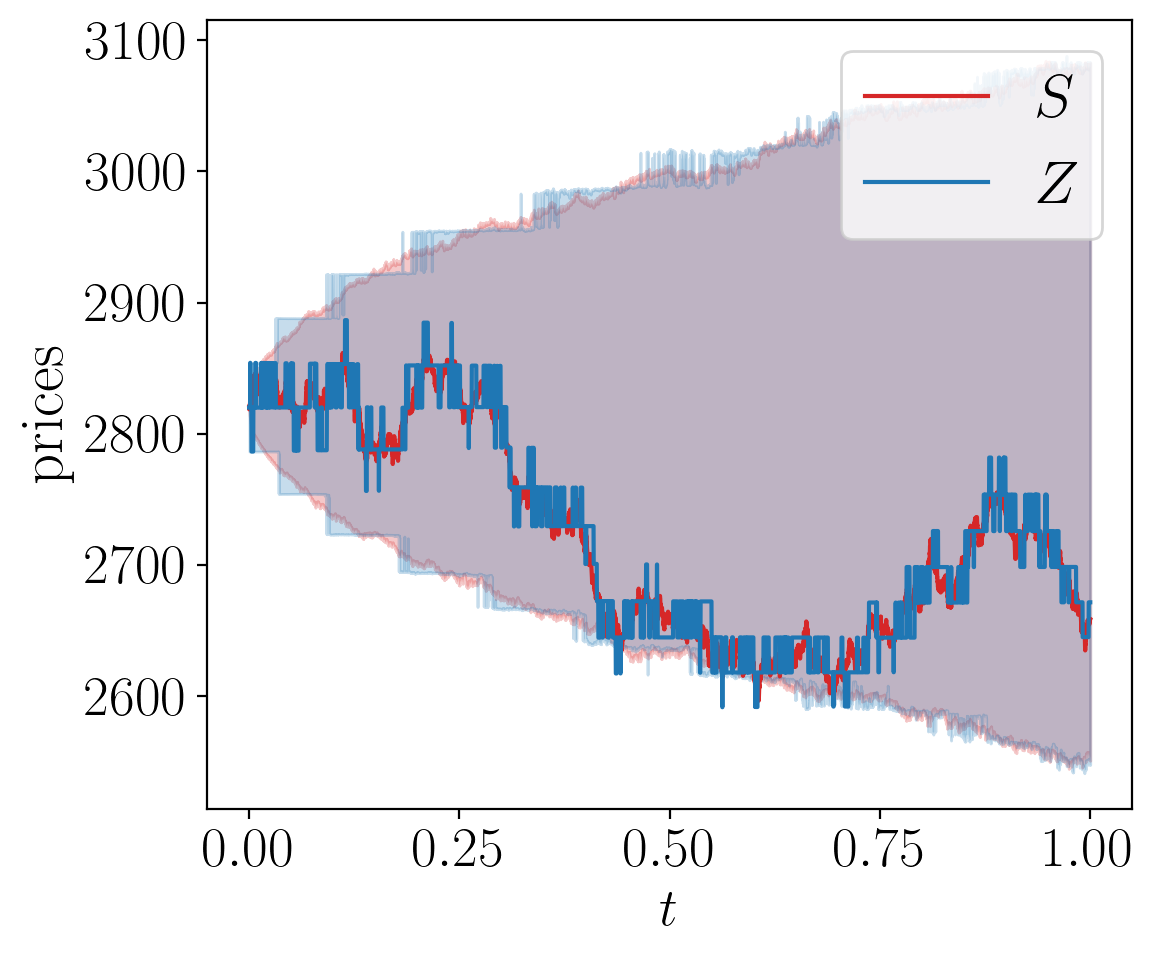

In [20]:
fig, axs = plt.subplots(1, 1, sharex=True, figsize=(6,5))
plt.plot(env.timesteps, S[:,nsim], label=r'$S$', color ='tab:red')
plt.plot(env.timesteps, Z[:,nsim], label=r'$Z$', color ='tab:blue')

plt.fill_between(env.timesteps,qtl_S[:,0],qtl_S[:,-1], color='tab:red', alpha=0.25)
plt.fill_between(env.timesteps,qtl_Z[:,0],qtl_Z[:,-1], color='tab:blue', alpha=0.25)

plt.xlabel(r'$t$', fontsize = fsL)
plt.ylabel(r'$\mathrm{prices}$', fontsize = fsL+3)
plt.legend(fontsize = fsL+3)
plt.tight_layout()
plt.savefig(f'figures/baseline-real-sim-S-Z-paths-{risk_type}.pdf', format="pdf", dpi=dpi)
plt.show()

In [21]:
values = [1,2,4]#,8,16]
colors = ['tab:red', 'tab:orange', 'skyblue', 'tab:green', 'tab:blue']

In [22]:
reload(plt_AMM)

<module 'plotting' from '/Users/leandrosb/Documents/GitHub/amm-make-take-fee/plotting.py'>

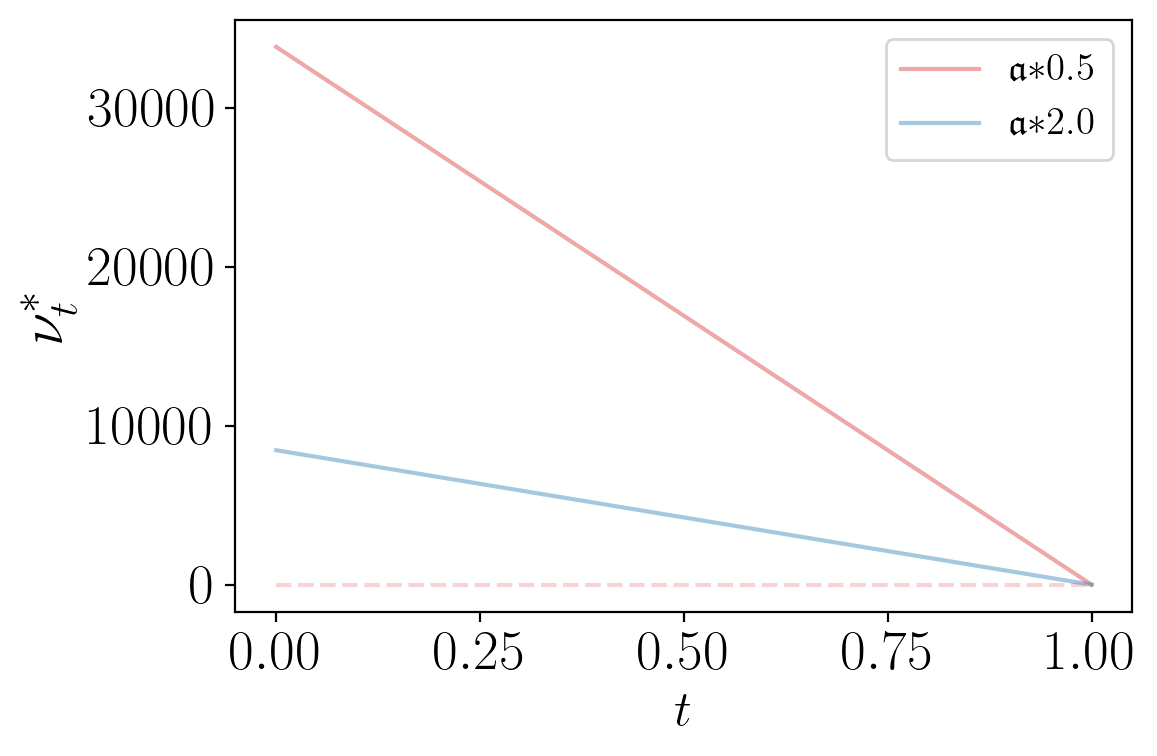

In [23]:
values = [0.5, 2.]
colors = ['tab:red','tab:blue','tab:orange', 'tab:green', 'skyblue']
plt_AMM.stress_parameter_and_show_nu(environment= utils.environment_exp, parameter = 'tempLP', values=values, colors = colors, params=params_env, 
                                     savefig = True, filename = f'stress-real-tempLP-{risk_type}', alpha=0.4, to_print=r'$\mathfrak{a}$', strag_vn = strag_vn, strag_LP = strag_LP)

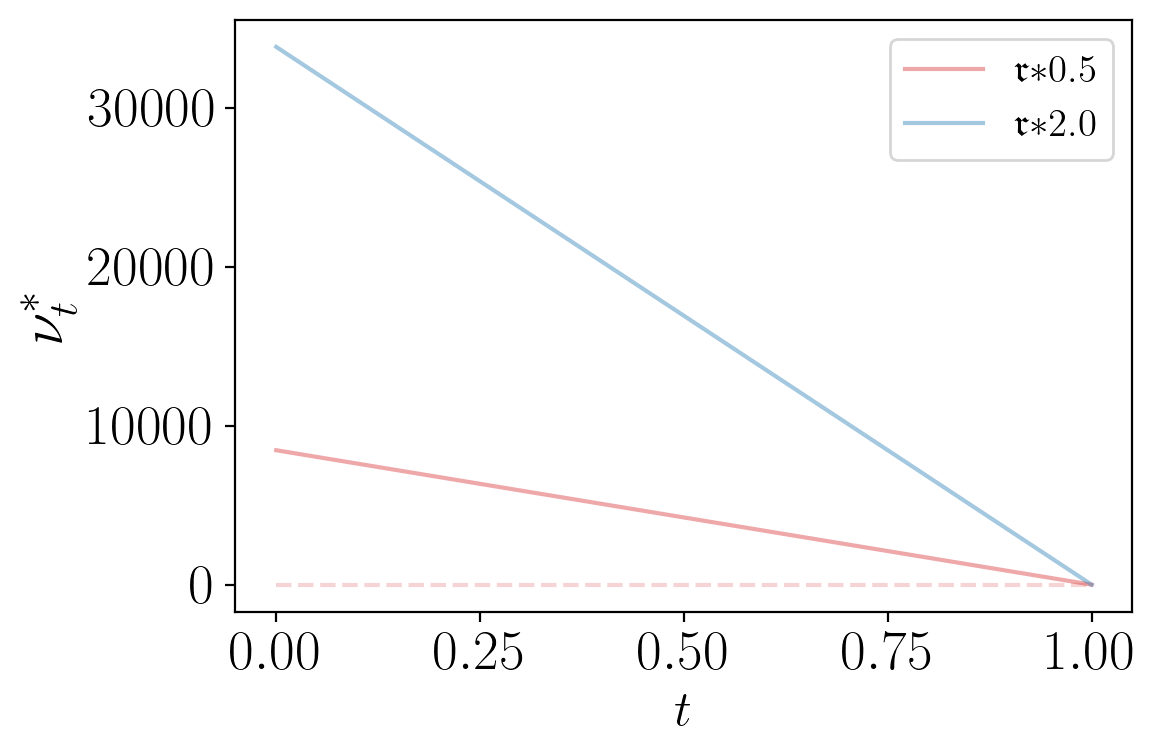

In [24]:
values = [0.5, 2.]
colors = ['tab:red','tab:blue','tab:orange', 'tab:green', 'skyblue']
plt_AMM.stress_parameter_and_show_nu(environment= utils.environment_exp, parameter = 'feeV', values=values, colors = colors, params=params_env, 
                                     savefig = True, filename = f'stress-real-feeV-{risk_type}', alpha=0.4, to_print=r'$\mathfrak{r}$', strag_vn = strag_vn, strag_LP = strag_LP)

### Histograms

In [25]:
nsims = 10_000
S, Y, Z, X, nu, wealth, perf, rew, venue_wealth, A_a_hist, A_b_hist, A_W_hist, A_B_hist, rew_drift_hist = env.simulate_venue(nsims=nsims, strag_LP=strag_LP, strag_vn=strag_vn, verbose = True)

In [26]:
xaux = (np.mean(venue_wealth[0,:]) - np.mean(wealth[-1,:]))/2

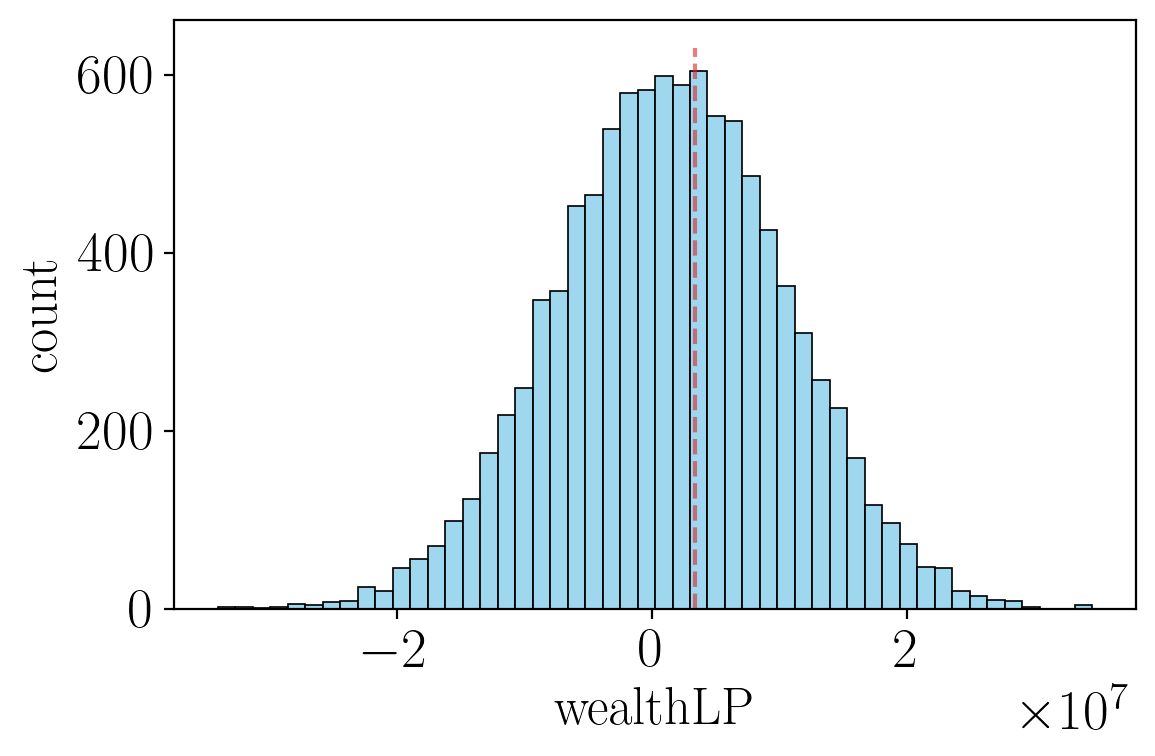

In [37]:
fig, axs = plt.subplots(1, 1, sharex=True, figsize=(6,4))

sns.histplot(data=wealth[-1,:] + xaux, bins = 50, kde=False, color="skyblue",  ax=axs, alpha =0.8)
plt.vlines(x = np.mean(wealth[-1,:]), ymin=0,ymax=630, linestyle='--', color='tab:red', alpha =0.6)
axs.set_xlabel(r'$\mathrm{wealth LP}$', fontsize = fsL)
axs.set_ylabel(r'$\mathrm{count}$', fontsize = fsL)
plt.tight_layout()
plt.savefig(f'figures/hist-real-sim-wealth-LP-{risk_type}.pdf', format="pdf", dpi=dpi)
plt.show()

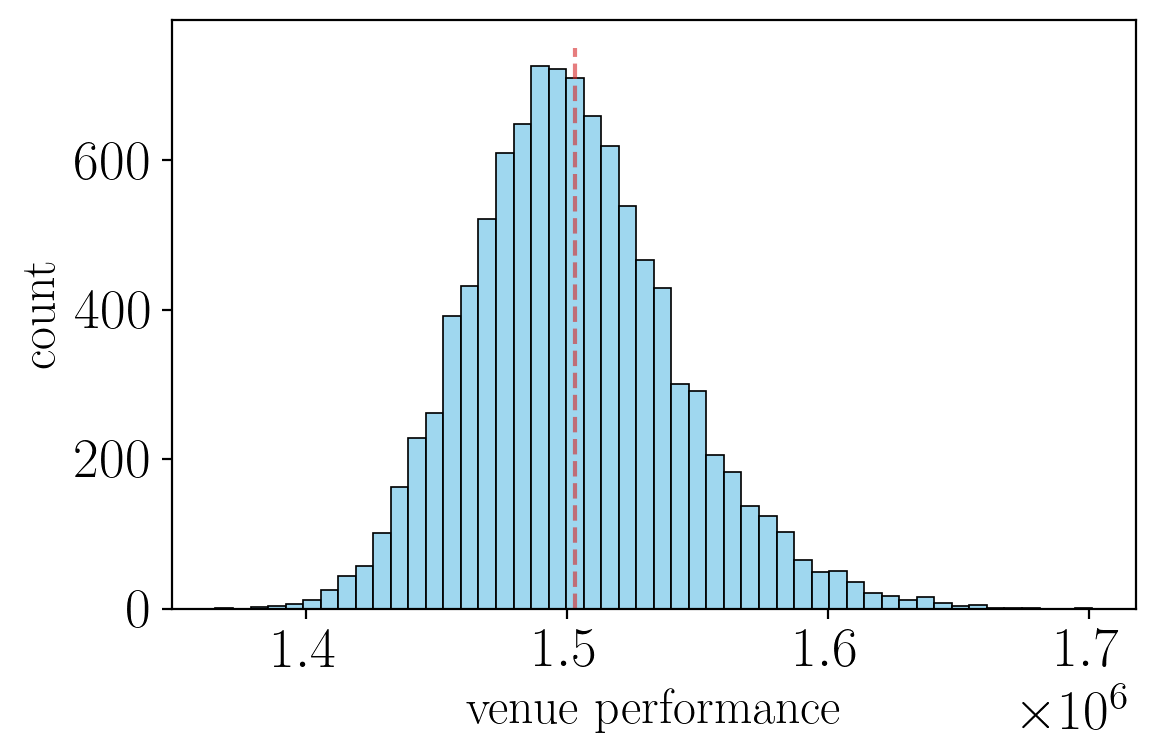

In [34]:
fig, axs = plt.subplots(1, 1, sharex=True, figsize=(6,4))

sns.histplot(data=venue_wealth[0,:]- xaux, bins = 50, kde=False, color="skyblue",  ax=axs, alpha =0.8)
plt.vlines(x = np.mean(venue_wealth[0,:])- xaux, ymin=0,ymax=750, linestyle='--', color='tab:red', alpha =0.6)

axs.set_xlabel(r'$\mathrm{venue~performance}$', fontsize = 18)
axs.set_ylabel(r'$\mathrm{count}$', fontsize = 18)
plt.tight_layout()
plt.savefig(f'figures/hist-real-venue-perf-{risk_type}.pdf', format="pdf", dpi=dpi)
plt.show()

In [29]:
import scipy as scipy

In [30]:
scipy.stats.ttest_1samp(wealth[0,:], popmean=0.)

TtestResult(statistic=37.110146418135784, pvalue=1.55588954585185e-282, df=9999)

In [31]:
scipy.stats.ttest_1samp(venue_wealth[0,:], popmean=0.)

TtestResult(statistic=-816.5942759414362, pvalue=0.0, df=9999)